# Exploratory analysis of global tropical cyclones, 2010–2025

In this phase we examine the processed NOAA International Best Track Archive for Climate Stewardship (IBTrACS) file. A row is a timestamped observation; `SID` identifies a cyclone and can recur many times. Accordingly, observation summaries describe recorded states and storm summaries count distinct cyclones. Repeated fixes within a track are dependent. The CSV contains observations dated from 2010 through 2025, including some storms assigned to the 2026 Southern Hemisphere season.

## 1. Setup and dataset overview

In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_PATH = Path("datasets/processed/cyclones_2010_2025.csv")
df = pd.read_csv(DATA_PATH, parse_dates=["ISO_TIME"], keep_default_na=False, na_values=[""])
required = {"SID", "SEASON", "YEAR", "BASIN", "ISO_TIME", "LAT", "LON", "TRACK_TYPE", "USA_WIND", "USA_PRES", "WMO_WIND", "WMO_PRES", "USA_SSHS", "STORM_SPEED", "STORM_DIR", "DIST2LAND"}

BASIN_ORDER = ["NA", "EP", "WP", "NI", "SI", "SP", "SA"]
BASIN_NAMES = {"NA": "North Atlantic", "EP": "East Pacific", "WP": "West Pacific", "NI": "North Indian", "SI": "South Indian", "SP": "South Pacific", "SA": "South Atlantic"}
BASIN_COLORS = dict(zip(BASIN_ORDER, sns.color_palette("colorblind", len(BASIN_ORDER))))
sns.set_theme(style="whitegrid", context="talk", palette="colorblind", font_scale=0.82)
plt.rcParams.update({"figure.dpi": 115, "axes.spines.top": False, "axes.spines.right": False, "grid.alpha": 0.22, "axes.titleweight": "bold"})

overview = pd.DataFrame({"Measure": ["Timestamped observations", "Distinct SID values", "Variables", "First timestamp", "Last timestamp", "Basins", "Calendar years", "Seasons"], "Value": [f"{len(df):,}", f"{df.SID.nunique():,}", str(df.shape[1]), str(df.ISO_TIME.min()), str(df.ISO_TIME.max()), ", ".join(BASIN_ORDER), f"{df.YEAR.min()}–{df.YEAR.max()}", f"{df.SEASON.min()}–{df.SEASON.max()}"]})
display(overview)
display(df.head(5))
display(df.dtypes.rename("dtype").to_frame().T)


,Measure,Value
0,Timestamped observations,"100,949"
1,Distinct SID values,"1,667"
2,Variables,22
3,First timestamp,2010-01-01 12:00:00
4,Last timestamp,2025-12-31 21:00:00
5,Basins,"NA, EP, WP, NI, SI, SP, SA"
6,Calendar years,2010–2025
7,Seasons,2010–2026


,SID,SEASON,YEAR,NUMBER,BASIN,SUBBASIN,NAME,ISO_TIME,NATURE,LAT,...,WMO_AGENCY,WMO_WIND,WMO_PRES,USA_WIND,USA_PRES,USA_SSHS,DIST2LAND,LANDFALL,STORM_SPEED,STORM_DIR
0,2010002S09096,2010,2010,1,SI,WA,EDZANI,2010-01-01 12:00:00,DS,-9.2,...,NaN,NaN,NaN,15.0,1010.0,-3,910,910.0,7,210
1,2010002S09096,2010,2010,1,SI,WA,EDZANI,2010-01-01 15:00:00,DS,-9.5,...,NaN,NaN,NaN,20.0,1007.0,-3,950,950.0,7,215
2,2010002S09096,2010,2010,1,SI,WA,EDZANI,2010-01-01 18:00:00,TS,-9.8,...,NaN,NaN,NaN,25.0,1004.0,-1,990,990.0,7,225
3,2010002S09096,2010,2010,1,SI,WA,EDZANI,2010-01-01 21:00:00,TS,-10.0,...,NaN,NaN,NaN,25.0,1004.0,-1,1024,1024.0,7,235
4,2010002S09096,2010,2010,1,SI,WA,EDZANI,2010-01-02 00:00:00,TS,-10.2,...,NaN,NaN,NaN,25.0,1004.0,-1,1059,1059.0,7,245


,SID,SEASON,YEAR,NUMBER,BASIN,SUBBASIN,NAME,ISO_TIME,NATURE,LAT,...,WMO_AGENCY,WMO_WIND,WMO_PRES,USA_WIND,USA_PRES,USA_SSHS,DIST2LAND,LANDFALL,STORM_SPEED,STORM_DIR
dtype,str,int64,int64,int64,str,str,str,datetime64[us],str,float64,...,str,float64,float64,float64,float64,int64,int64,float64,int64,int64


The dataset has **100,949 observations, 1,667 cyclone IDs, and 22 variables**. Its first and last timestamps are 2010-01-01 12:00 and 2025-12-31 21:00. Variables include identifiers and categories, UTC time, position, agency wind and pressure, storm motion, and land distance. The first five rows illustrate repeated measurements for one `SID`; they must not be counted as five storms.


## Variable Types and Descriptions

The table classifies the **meaning of each variable**, rather than its Pandas storage type. Definitions and units follow the [official NOAA IBTrACS v04 column documentation](https://www.ncei.noaa.gov/sites/default/files/2021-07/IBTrACS_v04_column_documentation.pdf); `YEAR` was added by the preprocessing notebook from `ISO_TIME`. One hectopascal (hPa) equals one millibar (mb). An interval scale supports meaningful differences but has no meaningful zero; a ratio scale also has a meaningful zero. Circular coordinates and directions require periodic treatment, as noted below.

| Variable | Description | Statistical type | Measurement scale |
|---|---|---|---|
| `SID` | IBTrACS identifier for a cyclone; repeated across its observations. | Identifier | Nominal |
| `SEASON` | NOAA-assigned cyclone season year; Southern Hemisphere seasons can be labeled with the following calendar year. | Temporal | Interval |
| `YEAR` | Calendar year of `ISO_TIME`, derived during preprocessing. | Temporal | Interval |
| `NUMBER` | System sequence number within a season; restarts each season and is not a physical quantity. | Identifier | Ordinal within a season |
| `BASIN` | Ocean basin of the cyclone's **current position**; `NA` means North Atlantic. | Qualitative nominal | Nominal |
| `SUBBASIN` | Subbasin of the current position; `MM` indicates that no subbasin is supplied. | Qualitative nominal | Nominal |
| `NAME` | Storm name reported by a source agency; names need not be unique. | Qualitative nominal | Nominal |
| `ISO_TIME` | Observation timestamp in Coordinated Universal Time (UTC). | Temporal | Interval |
| `NATURE` | Combined storm type, such as tropical, subtropical, extratropical, or disturbance. | Qualitative nominal | Nominal |
| `LAT` | Mean storm-center latitude in degrees north; negative values are south. | Quantitative continuous | Interval (spatial coordinate) |
| `LON` | Mean storm-center longitude in degrees east; wraps around the globe. | Quantitative continuous | Interval (circular spatial coordinate) |
| `TRACK_TYPE` | Track status or provenance, such as main, provisional, or spur. | Qualitative nominal | Nominal |
| `WMO_AGENCY` | Agency responsible for the WMO report at the current position. | Qualitative nominal | Nominal |
| `WMO_WIND` | Maximum sustained wind from the responsible WMO agency, in knots; averaging periods vary by agency. | Quantitative continuous | Ratio |
| `WMO_PRES` | Minimum central pressure reported by the responsible WMO agency, in hPa (mb). | Quantitative continuous | Ratio |
| `USA_WIND` | Maximum sustained wind from the selected US-agency source, in knots; US winds use a one-minute average. | Quantitative continuous | Ratio |
| `USA_PRES` | Minimum sea-level pressure from the selected US-agency source, in hPa (mb). | Quantitative continuous | Ratio |
| `USA_SSHS` | US-wind-based classification: −5 to −2 are status codes; −1 to 5 are ordered tropical intensity classes. | Qualitative nominal for status codes; qualitative ordinal for intensity classes | Nominal for −5 to −2; ordinal for −1 to 5 |
| `DIST2LAND` | Distance from the current storm-center position to the nearest qualifying land, in km. | Quantitative continuous | Ratio |
| `LANDFALL` | Minimum distance from the storm center to land over the near-future track, in km; zero indicates a center crossing in the source calculation. | Quantitative continuous | Ratio |
| `STORM_SPEED` | Translation speed calculated from track positions, in knots. | Quantitative continuous | Ratio |
| `STORM_DIR` | Direction of translation toward which the storm moves, in degrees clockwise from north (0° and 360° coincide). | Quantitative continuous (circular) | Interval modulo 360° |

The numeric storage of `NUMBER` and `USA_SSHS` does not make them continuous measurements. Likewise, longitude and movement direction must respect their circular boundaries when compared or summarized.


## 2. Data quality and measurement coverage

Empty CSV fields are missing. No values are imputed. `USA_WIND` and `WMO_WIND` are in knots, pressure is in hPa (equivalent to mb), `STORM_SPEED` is in knots, `DIST2LAND` is in km, and `STORM_DIR` is degrees clockwise from north. WMO winds may use agency-specific averaging periods; NOAA explicitly warns that they are not adjusted to a common duration. They are kept as separate measures.


In [4]:
missing = pd.DataFrame({"nonmissing": df.notna().sum(), "missing": df.isna().sum(), "missing_pct": df.isna().mean().mul(100).round(1)})
display(missing.sort_values("missing_pct", ascending=False))
coverage = df.groupby("BASIN", observed=True)[["USA_WIND", "USA_PRES", "WMO_WIND", "WMO_PRES"]].count().div(df.groupby("BASIN", observed=True).size(), axis=0).mul(100).reindex(BASIN_ORDER).round(1)
display(coverage.rename_axis("Basin"))
quality = pd.DataFrame({"check": ["Duplicate SID–ISO_TIME rows", "Cyclones visiting multiple basins", "Observation years disagreeing with ISO_TIME", "Provisional or spur observations"], "count": [int(df.duplicated(["SID", "ISO_TIME"]).sum()), int(df.groupby("SID")["BASIN"].nunique().gt(1).sum()), int(df.YEAR.ne(df.ISO_TIME.dt.year).sum()), int(df.TRACK_TYPE.ne("main").sum())]})
display(quality)
display(df.TRACK_TYPE.value_counts(dropna=False).rename("observations").to_frame())
range_cols = ["LAT", "LON", "USA_WIND", "USA_PRES", "WMO_WIND", "WMO_PRES", "STORM_SPEED", "STORM_DIR", "DIST2LAND", "USA_SSHS"]
display(df[range_cols].agg(["min", "median", "max"]).T.round(1))


,nonmissing,missing,missing_pct
WMO_WIND,43905,57044,56.5
WMO_PRES,49138,51811,51.3
WMO_AGENCY,49479,51470,51.0
USA_PRES,85918,15031,14.9
USA_WIND,85937,15012,14.9
LANDFALL,99286,1663,1.6
SID,100949,0,0.0
SEASON,100949,0,0.0
STORM_SPEED,100949,0,0.0
DIST2LAND,100949,0,0.0


,USA_WIND,USA_PRES,WMO_WIND,WMO_PRES
Basin,,,,
NA,100.0,100.0,51.7,51.7
EP,98.9,98.9,50.4,50.5
WP,80.2,80.2,29.1,46.3
NI,72.3,72.1,64.2,64.2
SI,74.6,74.6,46.4,46.3
SP,79.0,79.0,42.4,43.3
SA,100.0,100.0,51.0,51.0


,check,count
0,Duplicate SID–ISO_TIME rows,0
1,Cyclones visiting multiple basins,113
2,Observation years disagreeing with ISO_TIME,0
3,Provisional or spur observations,5006


,observations
TRACK_TYPE,
main,95943
US-PROVISIONAL,4877
PROVISIONAL,86
US-PROVISIONAL_spur,25
spur-merge,18


,min,median,max
LAT,-62.3,15.2,70.1
LON,-179.8,85.5,257.4
USA_WIND,10.0,40.0,185.0
USA_PRES,872.0,998.0,1021.0
WMO_WIND,3.0,40.0,185.0
WMO_PRES,872.0,997.0,1021.0
STORM_SPEED,0.0,9.0,87.0
STORM_DIR,0.0,260.0,360.0
DIST2LAND,0.0,573.0,4310.0
USA_SSHS,-5.0,-1.0,5.0


`WMO_WIND` is missing in **56.5%** of observations and `WMO_PRES` in **51.3%**; the USA measures are missing in about **14.9%**. Coverage is regionally uneven: `USA_WIND` is present for all North Atlantic observations but only 72.3% in the North Indian basin; `WMO_WIND` covers 29.1% in the West Pacific. Any cross-basin intensity comparison on complete cases selects different subsets of records. There are no duplicate storm timestamps, but **113 storms visit more than one basin**. Most records are `main`; **5,006** are provisional or spur records. These statuses may affect especially recent counts. `LON` spans −179.8° to 257.4° because the source mixes longitude conventions; geographic displays wrap it to −180°–180° without altering the data. The observed wind, pressure, and motion ranges merit inspection but are not automatically errors.


## 3. Numerical distributions

The table gives descriptive statistics on **observations**. A long track contributes more entries than a short one. The IQR is Q3 minus Q1. Wind and pressure use the USA series as separately reported measurements, with their nonmissing denominators shown.


,count,mean,median,std,q25,q75,IQR,min,max
USA wind (kt),85937.0,48.1,40.0,27.5,30.0,60.0,30.0,10.0,185.0
USA central pressure (hPa),85918.0,990.7,998.0,19.8,984.0,1004.0,20.0,872.0,1021.0
Translation speed (kt),100949.0,10.1,9.0,6.6,6.0,13.0,7.0,0.0,87.0
Distance to land (km),100949.0,768.9,573.0,680.3,196.0,1244.0,1048.0,0.0,4310.0
Latitude (°),100949.0,9.7,15.2,20.4,-11.9,22.5,34.4,-62.3,70.1
Longitude (source °),100949.0,44.9,85.5,106.9,-63.4,131.8,195.2,-179.8,257.4


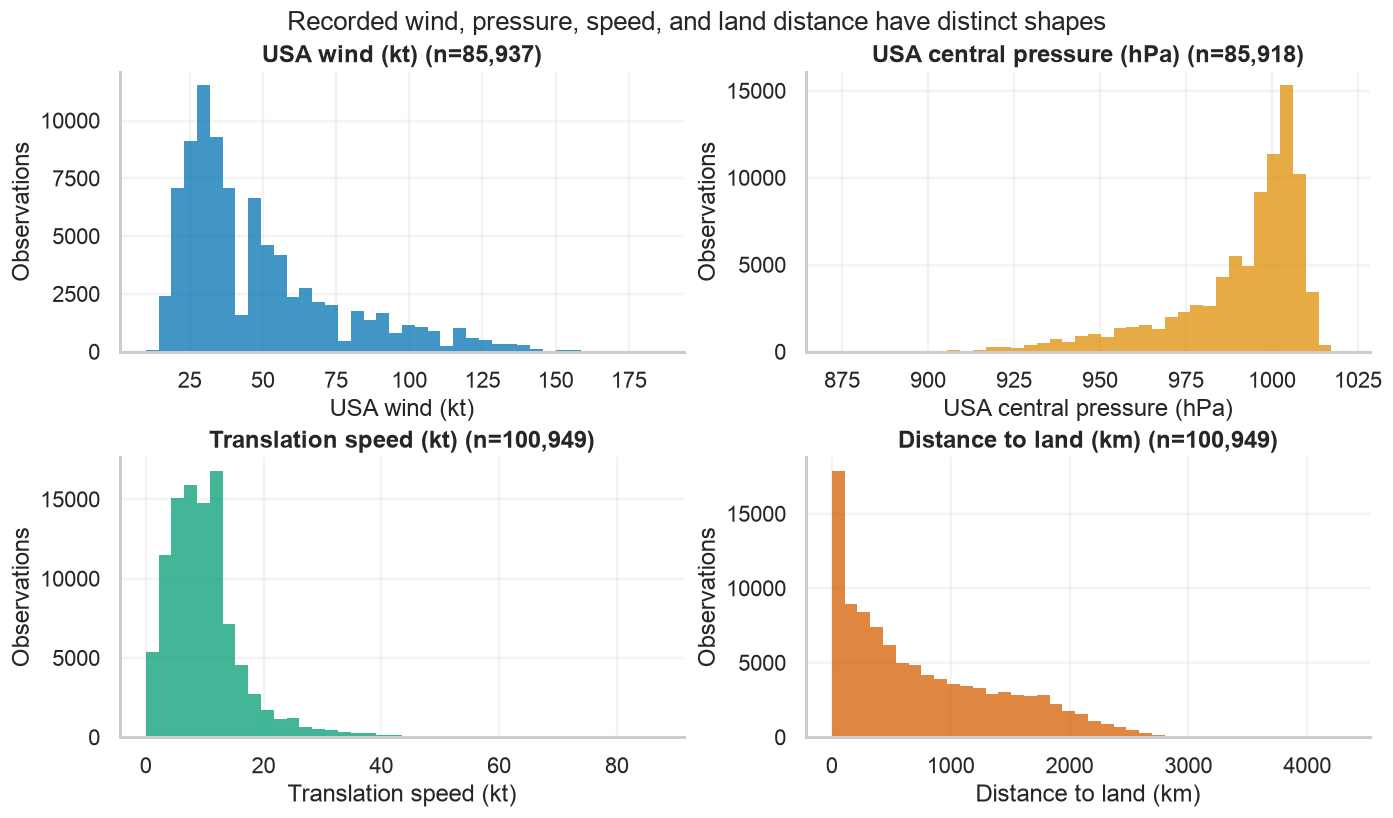

In [5]:
numeric = {"USA_WIND": "USA wind (kt)", "USA_PRES": "USA central pressure (hPa)", "STORM_SPEED": "Translation speed (kt)", "DIST2LAND": "Distance to land (km)", "LAT": "Latitude (°)", "LON": "Longitude (source °)"}
stats = df[list(numeric)].agg(["count", "mean", "median", "std", "min", "max"]).T
stats["q25"] = df[list(numeric)].quantile(.25)
stats["q75"] = df[list(numeric)].quantile(.75)
stats["IQR"] = stats.q75 - stats.q25
display(stats.rename(index=numeric)[["count", "mean", "median", "std", "q25", "q75", "IQR", "min", "max"]].round(1))
fig, axes = plt.subplots(2, 2, figsize=(12, 7), constrained_layout=True)
for ax, col, label, color in zip(axes.flat, ["USA_WIND", "USA_PRES", "STORM_SPEED", "DIST2LAND"], ["USA wind (kt)", "USA central pressure (hPa)", "Translation speed (kt)", "Distance to land (km)"], sns.color_palette("colorblind", 4)):
    values = df[col].dropna()
    sns.histplot(values, bins=40, ax=ax, color=color, edgecolor="none")
    ax.set(title=f"{label} (n={len(values):,})", xlabel=label, ylabel="Observations")
fig.suptitle("Recorded wind, pressure, speed, and land distance have distinct shapes", fontsize=16)
plt.show()


The USA wind distribution is concentrated at lower recorded speeds with a high-intensity tail; pressure has the opposite tail. Median translation speed is **9 kt** (IQR **6–13 kt**), with a few values above 35 kt. `DIST2LAND` is broad and right-skewed. A storm can spend many hours near land, so distance-to-land counts describe positions, not landfall events. The histogram counts reflect observation frequency as well as storm behavior; storm-level extrema are examined below.


## 4. Storm-level construction and temporal activity

A storm is assigned to the basin in which it has the **most observations**; alphabetical order resolves ties. This is a descriptive representative basin, not a claim that the storm formed there. `first` and `last` refer only to observations retained in this CSV, so duration is an **observed track span**. The available USA extrema remain missing when a storm has no USA measure. `USA_SSHS` includes negative status codes; peak category is the maximum recorded code and is interpreted only with its status meaning in mind.


In [6]:
ordered = df.sort_values(["SID", "ISO_TIME"])
g = ordered.groupby("SID", sort=False)
storm_df = g.agg(first=("ISO_TIME", "first"), last=("ISO_TIME", "last"), season=("SEASON", "first"), first_lat=("LAT", "first"), first_lon=("LON", "first"), observations=("SID", "size"), max_usa_wind=("USA_WIND", "max"), min_usa_pressure=("USA_PRES", "min"), max_usa_sshs=("USA_SSHS", "max"), mean_speed=("STORM_SPEED", "mean"))
storm_df["duration_days"] = (storm_df["last"] - storm_df["first"]).dt.total_seconds() / 86400
storm_df["first_year"] = storm_df["first"].dt.year
storm_df["hemisphere"] = np.where(storm_df.first_lat >= 0, "Northern", "Southern")
basin_visits = ordered.groupby(["SID", "BASIN"], sort=False).size().rename("fixes").reset_index().sort_values(["SID", "fixes", "BASIN"], ascending=[True, False, True])
storm_df["basin"] = basin_visits.drop_duplicates("SID").set_index("SID")["BASIN"]
assert len(storm_df) == df.SID.nunique()
assert storm_df.index.is_unique
assert storm_df.observations.sum() == len(df)
assert storm_df.duration_days.ge(0).all()
display(storm_df.head())
display(storm_df[["observations", "duration_days", "max_usa_wind", "min_usa_pressure", "mean_speed"]].notna().sum().rename("storm coverage").to_frame())


,first,last,season,first_lat,first_lon,observations,max_usa_wind,min_usa_pressure,max_usa_sshs,mean_speed,duration_days,first_year,hemisphere,basin
SID,,,,,,,,,,,,,,
2010002S09096,2010-01-01 12:00:00,2010-01-15 00:00:00,2010,-9.2,95.7,109,140.0,918.0,5,9.743119,13.50,2010,Southern,SI
2010018N07113,2010-01-18 00:00:00,2010-01-20 06:00:00,2010,6.9,113.2,19,30.0,1000.0,-1,9.263158,2.25,2010,Northern,WP
2010019S11123,2010-01-18 12:00:00,2010-01-24 06:00:00,2010,-10.9,123.0,47,65.0,974.0,1,4.914894,5.75,2010,Southern,SI
2010020S08163,2010-01-20 00:00:00,2010-01-31 00:00:00,2010,-8.3,163.0,90,45.0,987.0,0,9.888889,11.00,2010,Southern,SP
2010020S14147,2010-01-19 12:00:00,2010-01-23 12:00:00,2010,-14.1,146.6,33,NaN,NaN,-5,4.545455,4.00,2010,Southern,SP


,storm coverage
observations,1667
duration_days,1667
max_usa_wind,1538
min_usa_pressure,1538
mean_speed,1667


All 1,667 storms have track span and mean translation speed; **1,538** have both a USA wind maximum and pressure minimum. Their joint coverage permits a future storm-level multivariate analysis, but the subset and agency sourcing must be disclosed. A larger observation count is not an independent replication of a storm.


,storm_first_year,observations
2010,88,4906
2011,95,5612
2012,94,6273
2013,102,5958
2014,89,6060
2015,112,7298
2016,96,5882
2017,108,5672
2018,118,7713
2019,109,6950


,storms
season,
2010,82
2011,96
2012,92
2013,103
2014,91
2015,109
2016,99
2017,107
2018,114


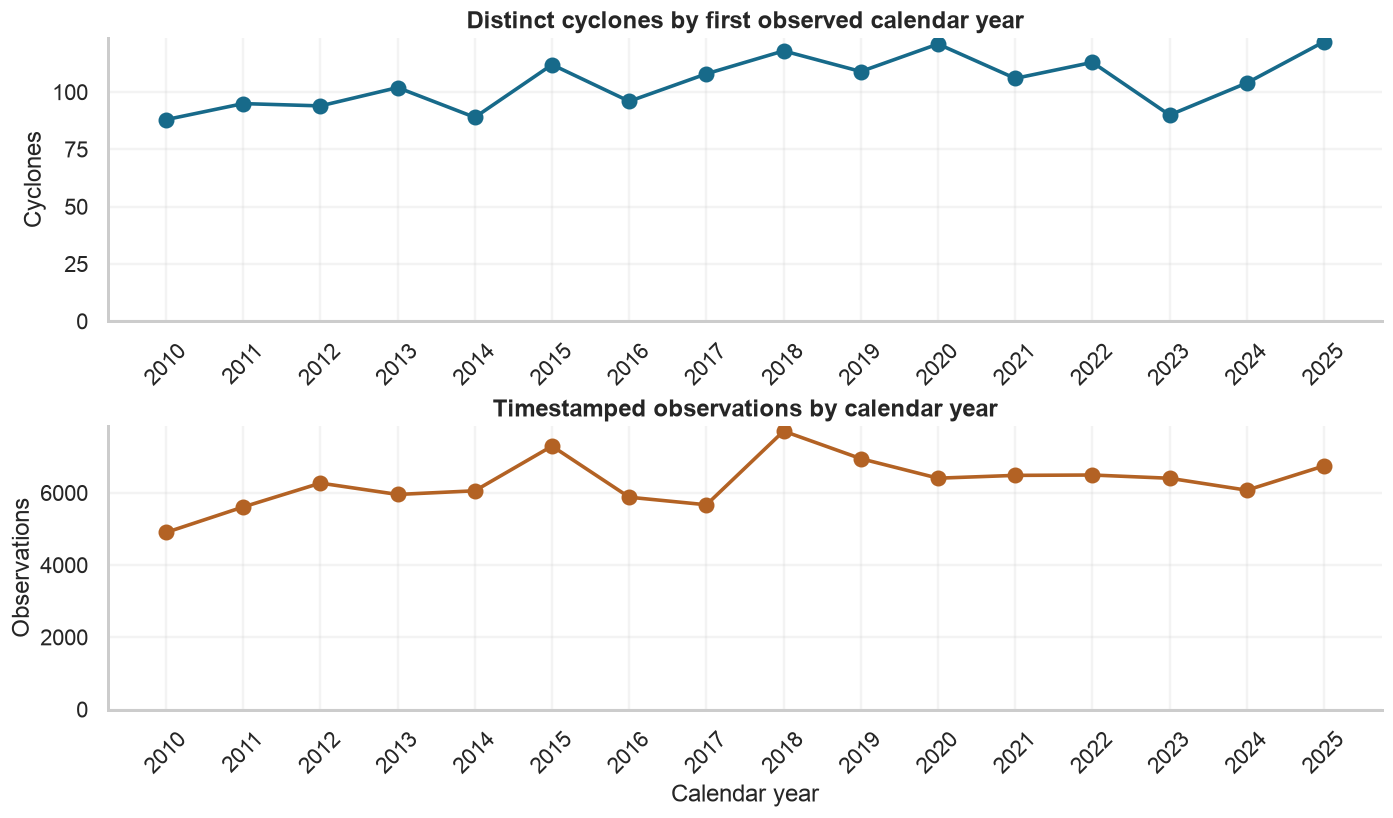

In [7]:
annual = pd.DataFrame({"storm_first_year": storm_df.groupby("first_year").size(), "observations": df.groupby("YEAR").size()})
season_counts = storm_df.groupby("season").size().rename("storms")
display(annual)
display(season_counts.to_frame())
fig, axes = plt.subplots(2, 1, figsize=(12, 7), constrained_layout=True)
axes[0].plot(annual.index, annual.storm_first_year, marker="o", color="#176A8A")
axes[0].set(title="Distinct cyclones by first observed calendar year", ylabel="Cyclones", xticks=annual.index)
axes[1].plot(annual.index, annual.observations, marker="o", color="#B36224")
axes[1].set(title="Timestamped observations by calendar year", xlabel="Calendar year", ylabel="Observations", xticks=annual.index)
for ax in axes:
    ax.tick_params(axis="x", rotation=45)
    ax.set_ylim(bottom=0)
plt.show()


Calendar-year first appearances range from **88 storms (2010)** to **122 (2025)**, while annual observation totals are a separate measure affected by duration, sampling, and track availability. `SEASON` is the storm's assigned meteorological season; NOAA assigns Southern Hemisphere systems beginning after July 1 to the following season. **Twelve** observed storms have `SEASON=2026` although this file stops in 2025. Those 2026-season counts are incomplete, and some boundary tracks may be truncated. No trend or climate attribution follows from this short, mixed-status series.


## 5. Geographic and seasonal structure

The basin bar chart counts storms by their representative basin and observations by each fix's actual basin. The monthly heatmap counts **distinct SID–calendar-month presences** within each basin, divided by the 16 calendar years. A storm crossing a month can appear in both months; it is not a genesis count. These denominators make hemispheric seasonality visible without equating fixes to cyclones.


,representative-basin cyclones,basin observations
NA,289,16870
EP,318,17793
WP,469,30083
NI,166,5799
SI,274,20818
SP,149,9490
SA,2,96


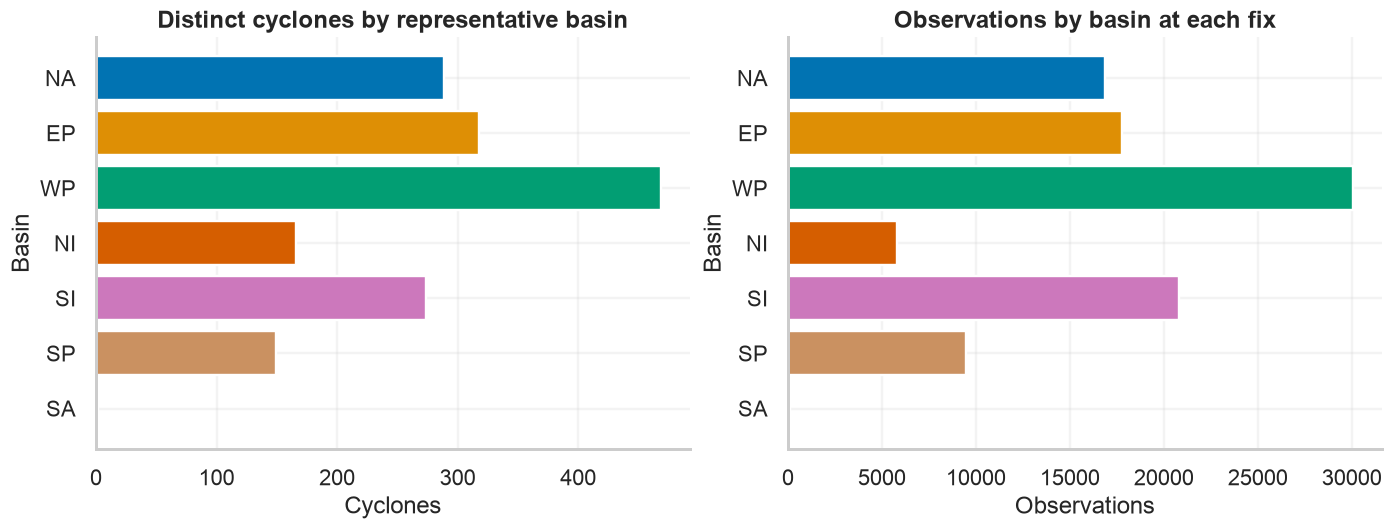

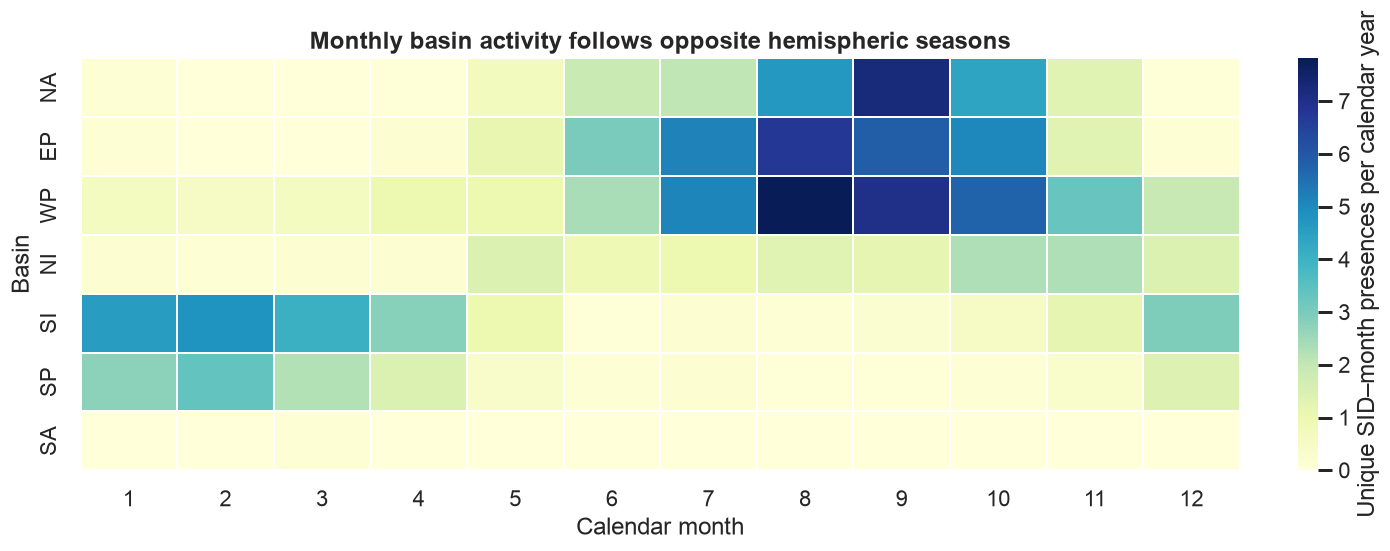

In [8]:
basin_storms = storm_df.basin.value_counts().reindex(BASIN_ORDER, fill_value=0)
basin_obs = df.BASIN.value_counts().reindex(BASIN_ORDER, fill_value=0)
display(pd.DataFrame({"representative-basin cyclones": basin_storms, "basin observations": basin_obs}))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
for ax, vals, title, xlabel in zip(axes, [basin_storms, basin_obs], ["Distinct cyclones by representative basin", "Observations by basin at each fix"], ["Cyclones", "Observations"]):
    ax.barh(BASIN_ORDER[::-1], vals.iloc[::-1], color=[BASIN_COLORS[b] for b in BASIN_ORDER[::-1]])
    ax.set(title=title, xlabel=xlabel, ylabel="Basin")
    ax.set_xlim(left=0)
plt.show()
monthly = df.assign(month=df.ISO_TIME.dt.month).groupby(["BASIN", "month"])["SID"].nunique().unstack(fill_value=0).reindex(BASIN_ORDER).reindex(columns=range(1,13), fill_value=0)
fig, ax = plt.subplots(figsize=(12, 4.5), constrained_layout=True)
sns.heatmap(monthly.div(16), cmap="YlGnBu", linewidths=.25, cbar_kws={"label": "Unique SID–month presences per calendar year"}, ax=ax)
ax.set(title="Monthly basin activity follows opposite hemispheric seasons", xlabel="Calendar month", ylabel="Basin")
plt.show()


The West Pacific has the largest representative-basin count (**469**), followed by the East Pacific (**318**) and North Atlantic (**289**). The South Atlantic contributes only **2** storms, so its summary estimates are unstable. Northern basins peak around late boreal summer; the South Indian and South Pacific concentrate in austral summer. These are month-presence frequencies, not unique storms formed in each month. A cyclone that crosses basins can contribute fixes to multiple basin rows, but only one bar in the storm chart.


month,1,2,3,4,5,6,7,8,9,10,11,12
hemisphere,,,,,,,,,,,,
Northern,16,10,13,21,65,127,208,306,324,256,124,54
Southern,115,126,96,65,21,3,6,3,5,10,23,65


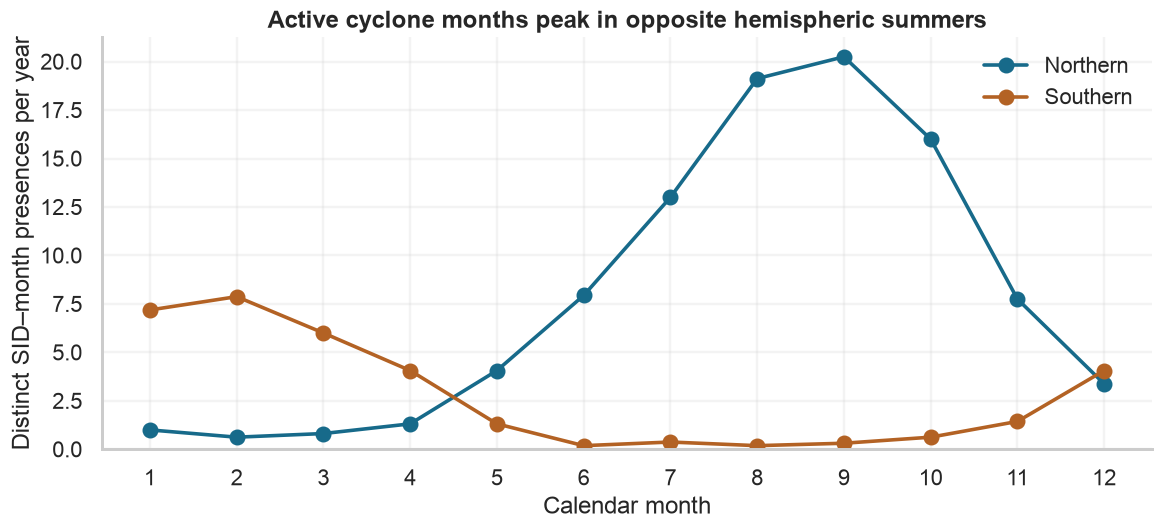

In [9]:
hemisphere_month = df.assign(month=df.ISO_TIME.dt.month, hemisphere=df.SID.map(storm_df.hemisphere)).groupby(["hemisphere", "month"])["SID"].nunique().unstack(fill_value=0).reindex(["Northern", "Southern"])
display(hemisphere_month)
fig, ax = plt.subplots(figsize=(10, 4.5), constrained_layout=True)
for hemisphere, color in [("Northern", "#176A8A"), ("Southern", "#B36224")]:
    ax.plot(hemisphere_month.columns, hemisphere_month.loc[hemisphere] / 16, marker="o", label=hemisphere, color=color)
ax.set(title="Active cyclone months peak in opposite hemispheric summers", xlabel="Calendar month", ylabel="Distinct SID–month presences per year", xticks=range(1, 13), ylim=(0, None))
ax.legend(frameon=False)
plt.show()


Storms are assigned to a hemisphere from their first retained latitude. Northern storm-month presence peaks in **September** (324 distinct SID–month presences over 16 years); Southern presence peaks in **February** (126). These counts reflect months with recorded activity, not genesis or independent month-long events. A storm crossing the equator keeps its first-observed hemisphere in this summary.


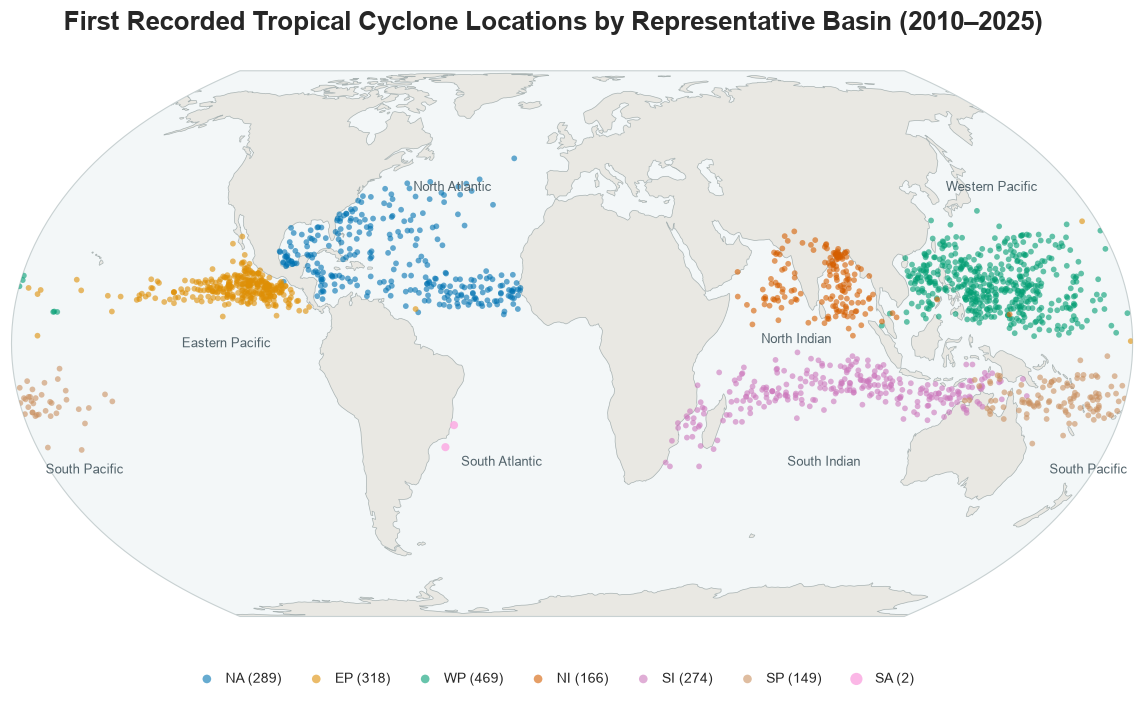

In [10]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature

genesis = storm_df.copy()
genesis["plot_lon"] = ((genesis.first_lon + 180) % 360) - 180
fig, ax = plt.subplots(figsize=(13, 6.5), subplot_kw={"projection": ccrs.EqualEarth()})
fig.subplots_adjust(top=.88, bottom=.15)
ax.set_global()
ax.set_facecolor("#f3f7f8")
ax.add_feature(cfeature.LAND.with_scale("110m"), facecolor="#e9e8e3", edgecolor="none", zorder=1)
ax.coastlines(resolution="110m", color="#a9b3b3", linewidth=.45, zorder=2)
ax.spines["geo"].set_edgecolor("#c8d1d2")
ax.spines["geo"].set_linewidth(.7)
for basin in BASIN_ORDER:
    part = genesis.loc[genesis.basin.eq(basin)]
    ax.scatter(part.plot_lon, part.first_lat, s=26 if basin == "SA" else 13, alpha=.9 if basin == "SA" else .6, color=BASIN_COLORS[basin], edgecolors="none", label=f"{basin} ({len(part)})", transform=ccrs.PlateCarree(), rasterized=True, zorder=5 if basin == "SA" else 3)

ocean_labels = [(-43, 39, "North Atlantic"), (-111, 0, "Eastern Pacific"), (151, 39, "Western Pacific"), (72, 1, "North Indian"), (86, -29, "South Indian"), (178, -31, "South Pacific"), (-168, -31, "South Pacific"), (-24, -29, "South Atlantic")]
for lon, lat, name in ocean_labels:
    ax.text(lon, lat, name, transform=ccrs.PlateCarree(), ha="center", va="center", fontsize=8, color="#52636b", zorder=4)
fig.suptitle("First Recorded Tropical Cyclone Locations by Representative Basin (2010–2025)", x=.5, y=.96, fontsize=16, fontweight="bold")
fig.legend(*ax.get_legend_handles_labels(), loc="lower center", bbox_to_anchor=(.5, .04), ncol=7, frameon=False, fontsize=9, markerscale=1.5, handletextpad=.3, columnspacing=1.4)
plt.show()


First recorded cyclone positions cluster over the tropical oceans, especially in the western Pacific, eastern Pacific, and North Atlantic, while the South Atlantic has very few storms. The land outlines make these basin patterns and the contrast between Northern and Southern Hemisphere activity easier to locate. Each point represents one cyclone, colored by its representative basin (the basin with the most recorded observations), which may differ from the basin of its first position. “First recorded” means the first observation retained in this 2010–2025 window, not necessarily physical genesis.


## 6. Intensity, pressure, and category semantics

`USA_SSHS` codes **−5 unknown, −4 post-tropical, −3 miscellaneous disturbance, −2 subtropical, −1 tropical depression, 0 tropical storm, and 1–5 hurricane-equivalent categories**. The positive categories are based on US-agency one-minute sustained wind. Negative values are statuses, not negative intensities. A row-level distribution answers how often a status was recorded; a storm-level maximum answers the highest recorded code per `SID`. These are displayed separately.


,observations,cyclones at maximum code
Unknown,14595,129
Post-tropical,3165,1
Other disturbance,15546,7
Subtropical,1451,11
Depression,16714,112
Tropical storm,30501,662
Cat 1,7857,222
Cat 2,4267,123
Cat 3,3175,97
Cat 4,3023,205


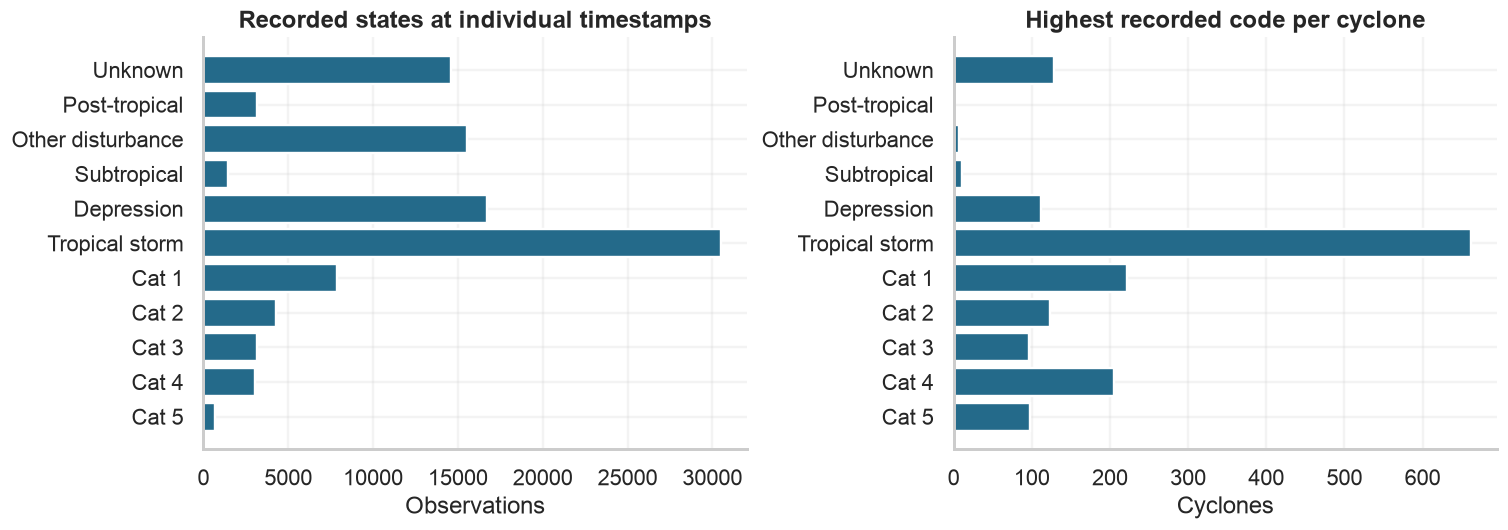

,paired_observations,median_USA_minus_WMO_kt,pearson_r
0,39461,0.0,0.96


In [11]:
category_labels = {-5:"Unknown", -4:"Post-tropical", -3:"Other disturbance", -2:"Subtropical", -1:"Depression", 0:"Tropical storm", 1:"Cat 1", 2:"Cat 2", 3:"Cat 3", 4:"Cat 4", 5:"Cat 5"}
cat_codes = list(category_labels)
cat_table = pd.DataFrame({"observations": df.USA_SSHS.value_counts().reindex(cat_codes, fill_value=0), "cyclones at maximum code": storm_df.max_usa_sshs.value_counts().reindex(cat_codes, fill_value=0)})
cat_table.index = [category_labels[k] for k in cat_codes]
display(cat_table)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
for ax, col, title in zip(axes, cat_table.columns, ["Recorded states at individual timestamps", "Highest recorded code per cyclone"]):
    ax.barh(cat_table.index[::-1], cat_table[col].iloc[::-1], color="#246A8A")
    ax.set(title=title, xlabel="Observations" if col == "observations" else "Cyclones", xlim=(0, None))
plt.show()
paired_wind = df[["USA_WIND", "WMO_WIND"]].dropna()
display(pd.DataFrame({"paired_observations": [len(paired_wind)], "median_USA_minus_WMO_kt": [(paired_wind.USA_WIND - paired_wind.WMO_WIND).median()], "pearson_r": [paired_wind.corr().iloc[0,1]]}).round(2))


The most frequent timestamp category is tropical storm (**30,501 observations**); category 5 occurs at **655** timestamps. The status categories are substantial, especially “unknown” and “other disturbance,” so treating all codes as an ordinal intensity scale would be invalid. USA and WMO wind values coexist for **39,461** fixes and are strongly associated, but their differences cannot be interpreted as instrument error alone: averaging periods and agency sources vary. The category bars use different denominators and must not be compared as percentages of a common population.


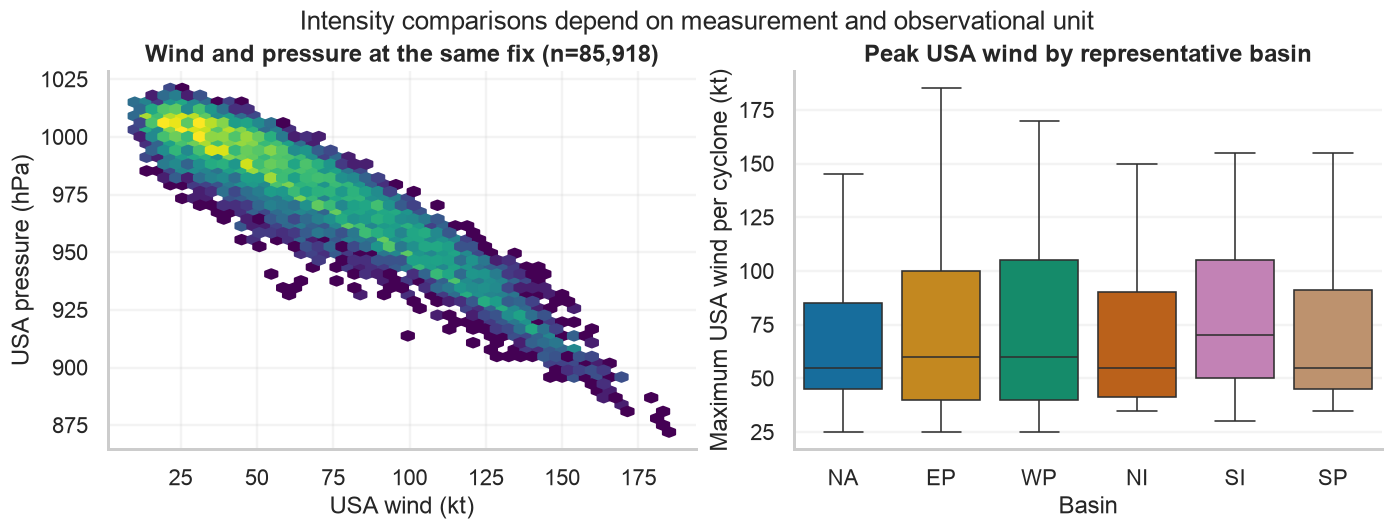

In [12]:
pair = df[["USA_WIND", "USA_PRES"]].dropna()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
axes[0].hexbin(pair.USA_WIND, pair.USA_PRES, gridsize=45, bins="log", mincnt=1, cmap="viridis")
axes[0].set(title=f"Wind and pressure at the same fix (n={len(pair):,})", xlabel="USA wind (kt)", ylabel="USA pressure (hPa)")
box_data = storm_df.loc[storm_df.basin.ne("SA"), ["basin", "max_usa_wind"]].dropna()
sns.boxplot(data=box_data, x="basin", y="max_usa_wind", order=[b for b in BASIN_ORDER if b != "SA"], palette=BASIN_COLORS, hue="basin", hue_order=[b for b in BASIN_ORDER if b != "SA"], legend=False, showfliers=False, ax=axes[1])
axes[1].set(title="Peak USA wind by representative basin", xlabel="Basin", ylabel="Maximum USA wind per cyclone (kt)")
fig.suptitle("Intensity comparisons depend on measurement and observational unit", fontsize=16)
plt.show()


The paired-fix USA wind and pressure relationship is strongly negative (**Pearson r = −0.948**, 85,918 paired fixes), consistent with more intense systems having lower central pressure. This is a descriptive within-dataset association, with many dependent fixes per storm. Basin peak-wind boxes compare cyclones, but uneven USA coverage remains a selection issue; South Atlantic is omitted from boxes because it has only two storms. The absence of outlier markers in the box plot improves central-distribution readability; extrema remain in the summary table.


## 7. Observed lifecycle and movement

Storm-level track span is calculated from first to last retained fix. It may include non-tropical phases, observation gaps, and records cut by the date boundaries, so it is not a validated physical lifetime. The following comparisons use one row per storm. Direction remains circular: 0° and 360° are the same direction, so an arithmetic mean would be misleading.


,count,mean,median,std,q25,q75,IQR,min,max
duration_days,1667.0,7.4,6.8,4.3,4.2,9.8,5.5,0.4,38.0
observations,1667.0,60.6,56.0,34.6,35.0,79.0,44.0,4.0,305.0
max_usa_wind,1538.0,72.5,60.0,35.7,45.0,100.0,55.0,25.0,185.0
min_usa_pressure,1538.0,973.7,983.0,27.8,956.0,996.0,40.0,872.0,1014.0
mean_speed,1667.0,10.0,9.4,4.0,7.2,12.1,5.0,0.0,34.0


,duration_days,max_usa_wind,min_usa_pressure
basin,,,
NA,5.8,55.0,992.0
EP,6.2,60.0,991.0
WP,7.8,60.0,979.0
NI,3.5,55.0,982.0
SI,8.8,70.0,974.0
SP,6.5,55.0,982.0
SA,5.9,45.0,992.0


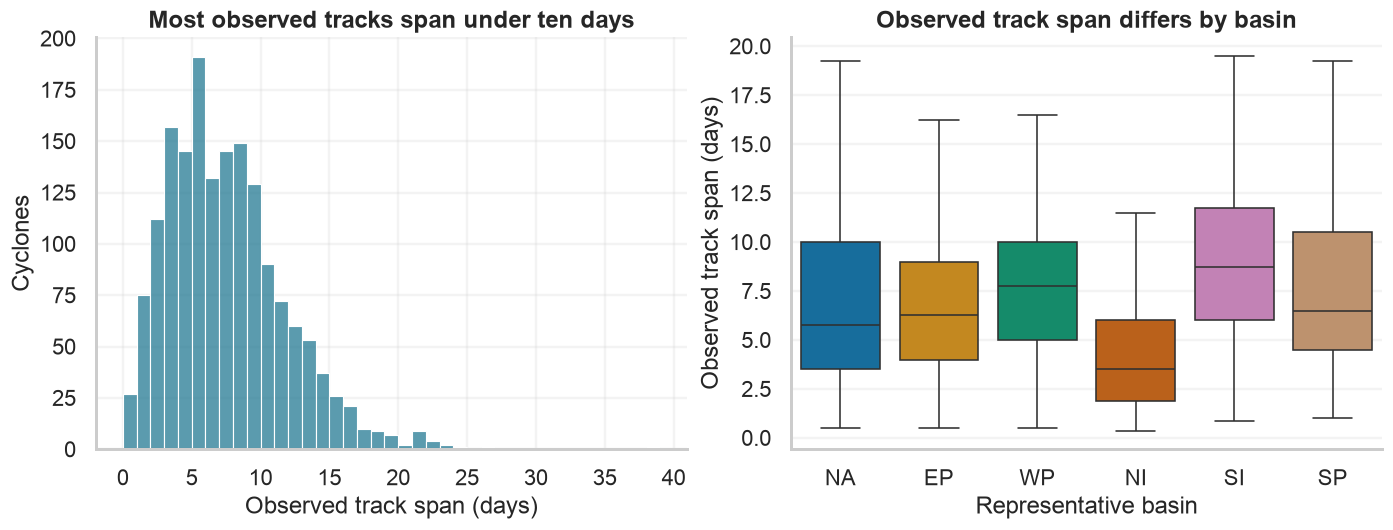

In [13]:
storm_stats = storm_df[["duration_days", "observations", "max_usa_wind", "min_usa_pressure", "mean_speed"]].agg(["count", "mean", "median", "std", "min", "max"]).T
storm_stats["q25"] = storm_df[["duration_days", "observations", "max_usa_wind", "min_usa_pressure", "mean_speed"]].quantile(.25)
storm_stats["q75"] = storm_df[["duration_days", "observations", "max_usa_wind", "min_usa_pressure", "mean_speed"]].quantile(.75)
storm_stats["IQR"] = storm_stats.q75 - storm_stats.q25
display(storm_stats[["count", "mean", "median", "std", "q25", "q75", "IQR", "min", "max"]].round(1))
display(storm_df.groupby("basin")[["duration_days", "max_usa_wind", "min_usa_pressure"]].median().reindex(BASIN_ORDER).round(1))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
sns.histplot(storm_df.duration_days, bins=np.arange(0, 40, 1), color="#247A93", ax=axes[0])
axes[0].set(title="Most observed tracks span under ten days", xlabel="Observed track span (days)", ylabel="Cyclones")
sns.boxplot(data=storm_df.loc[storm_df.basin.ne("SA")], x="basin", y="duration_days", order=[b for b in BASIN_ORDER if b != "SA"], hue="basin", hue_order=[b for b in BASIN_ORDER if b != "SA"], palette=BASIN_COLORS, legend=False, showfliers=False, ax=axes[1])
axes[1].set(title="Observed track span differs by basin", xlabel="Representative basin", ylabel="Observed track span (days)")
plt.show()


The median observed track span is **6.75 days** (IQR **4.25–9.75**), with a right tail reaching **38 days**. The North Indian median is **3.5 days**, versus **8.8** in the South Indian basin. These descriptive differences could reflect geography, track handling, or reporting as well as meteorology. The file begins with one storm already observed at its first retained timestamp and ends with several storms still present; both boundaries can truncate durations.


,observations
N–NE,10598
NE–E,9402
E–SE,7645
SE–S,6500
S–SW,5958
SW–W,14540
W–NW,32579
NW–N,13727


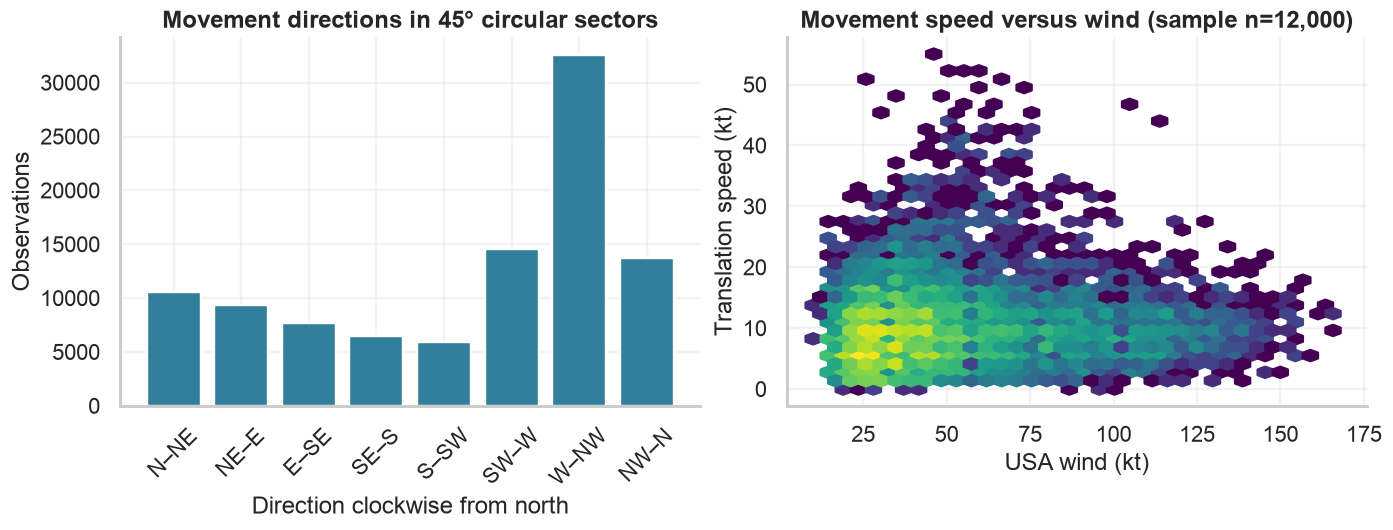

In [14]:
directions = pd.cut(df.STORM_DIR.mod(360), bins=np.arange(0, 361, 45), right=False, include_lowest=True, labels=["N–NE", "NE–E", "E–SE", "SE–S", "S–SW", "SW–W", "W–NW", "NW–N"])
direction_counts = directions.value_counts().reindex(directions.cat.categories)
display(direction_counts.rename("observations").to_frame())
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
axes[0].bar(direction_counts.index, direction_counts.values, color="#317F9B")
axes[0].set(title="Movement directions in 45° circular sectors", xlabel="Direction clockwise from north", ylabel="Observations")
axes[0].tick_params(axis="x", rotation=45)
speed_sample = df.loc[df.USA_WIND.notna(), ["STORM_SPEED", "USA_WIND"]].sample(n=min(12000, df.USA_WIND.notna().sum()), random_state=42)
axes[1].hexbin(speed_sample.USA_WIND, speed_sample.STORM_SPEED, gridsize=35, bins="log", mincnt=1, cmap="viridis")
axes[1].set(title=f"Movement speed versus wind (sample n={len(speed_sample):,})", xlabel="USA wind (kt)", ylabel="Translation speed (kt)")
plt.show()


Movement spans all compass sectors; the 45° bins preserve the circular boundary at north. They count fixes, so long storms weigh more. The speed–wind panel uses a reproducible sample to reduce rendering cost and overplotting; it is exploratory, not evidence that intensity causes motion. `DIST2LAND` is proximity to a particular land mask, not proof of landfall. `LANDFALL` is a forward-looking proximity measure and is not converted to an event count here.


## 8. Exploratory relationships and multivariate readiness

Correlations below are computed only on valid pairs. The storm-level matrix uses one row per `SID`; the fix-level wind–pressure coefficient above answers a different question. Correlation measures association, not causation, and peak values may occur at different timestamps.


,feature,available_storms,complete_case_storms
0,duration_days,1667,1538
1,max_usa_wind,1538,1538
2,min_usa_pressure,1538,1538
3,mean_speed,1667,1538


,duration_days,max_usa_wind,min_usa_pressure,mean_speed
duration_days,1.00,0.57,-0.57,-0.02
max_usa_wind,0.57,1.00,-0.97,0.08
min_usa_pressure,-0.57,-0.97,1.00,-0.09
mean_speed,-0.02,0.08,-0.09,1.00


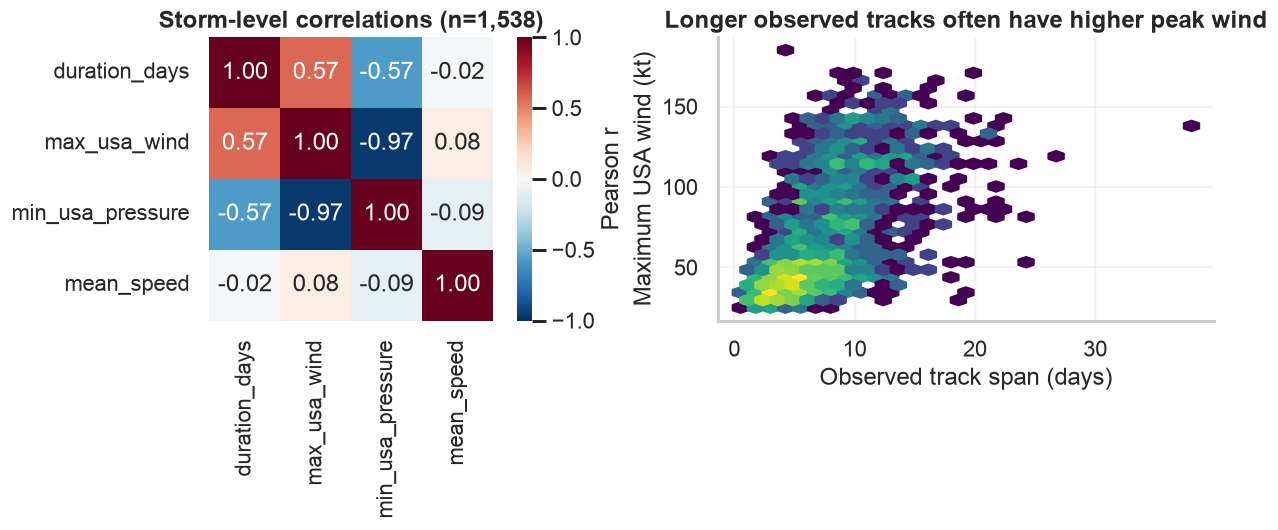

In [15]:
features = ["duration_days", "max_usa_wind", "min_usa_pressure", "mean_speed"]
complete = storm_df[features].dropna()
display(pd.DataFrame({"feature": features, "available_storms": [storm_df[x].notna().sum() for x in features], "complete_case_storms": len(complete)}))
display(complete.corr().round(2))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)
sns.heatmap(complete.corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True, ax=axes[0], cbar_kws={"label": "Pearson r"})
axes[0].set(title=f"Storm-level correlations (n={len(complete):,})")
axes[1].hexbin(complete.duration_days, complete.max_usa_wind, gridsize=30, bins="log", mincnt=1, cmap="viridis")
axes[1].set(title="Longer observed tracks often have higher peak wind", xlabel="Observed track span (days)", ylabel="Maximum USA wind (kt)")
plt.show()


On 1,538 complete storms, maximum USA wind and minimum USA pressure correlate at about **−0.97**; the extrema need not coincide in time, so this is a track-summary association. Observed duration and peak wind correlate at about **0.57**. Longer tracks offer more opportunity to record a high maximum, and reporting/track-selection can contribute. Wind and pressure are strongly redundant for a distance-based analysis. The four candidate features have different units and scales; standardization would be necessary if used jointly. Latitude or basin could add geographic information, but encoding them in a Euclidean distance may make geography dominate the scientific question.


## 9. Key exploratory findings

- **Coverage is the central measurement limitation.** USA wind and pressure are available for about 85% of fixes and 1,538 of 1,667 storms; WMO coverage is lower and varies markedly by basin. NOAA does not harmonize WMO wind averaging periods.
- **Geographic activity is uneven.** The West Pacific has 469 representative-basin storms; the South Atlantic has only two. Monthly presence follows opposite Northern and Southern Hemisphere seasons. Basin-switching affects 113 storms.
- **Time aggregates answer different questions.** First observed calendar-year storm counts range from 88 to 122, whereas observation counts reflect track span and sampling. Southern Hemisphere season assignment produces 12 season-2026 storms in this 2010–2025 observation window.
- **Intensity and lifecycle are related descriptively.** Paired USA wind and pressure at fixes show a strong inverse association, while longer observed tracks tend to have higher recorded peak wind. Neither pattern establishes a causal mechanism. The median observed span is 6.75 days, with substantial basin variation.